# Снижение размерности: MNIST, сжатие картинок, фон на видео

В этом ноутбуке:

1. Коротко про теорию: проклятие размерности, PCA, SVD, NMF, LLE, t-SNE, UMAP.
2. MNIST: сжимаем картинки цифр до 2 чисел шестью методами и сравниваем, какой лучше разделяет классы.
3. Сжатие картинок через SVD: сколько компонент нужно, чтобы картинка выглядела нормально.
4. Отделение фона на видео с камеры через SVD.
5. Бонус: лица из CelebA. Добавляем и убираем улыбку с помощью PCA, смотрим на компоненты NMF.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import umap
from joblib import dump

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.decomposition import PCA, TruncatedSVD, NMF
from sklearn.manifold import TSNE, LocallyLinearEmbedding
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, silhouette_score

os.makedirs('images', exist_ok=True)
os.makedirs('models', exist_ok=True)

## 1. Теория

### 1.1 Для каких моделей важно проклятие размерности

Когда признаков становится много, точки оказываются далеко друг от друга, и расстояния между ними почти не отличаются.

- **kNN** страдает сильнее всех: он целиком построен на расстояниях, а в большой размерности "ближайший" сосед почти так же далеко, как и любой другой.
- **Линейные модели без регуляризации:** если признаков столько же, сколько объектов, или больше, модель может подогнаться под любой шум. Это было видно на полиномах 10-й степени в линейных моделях. Ridge и Lasso помогают, Lasso ещё и выкидывает лишние признаки.
- **Деревья и ансамбли** страдают меньше: в каждом узле выбирается один лучший признак, и бесполезные признаки чаще просто не используются. Но если шумовых признаков очень много, какой-то из них случайно может дать хорошее разбиение, и дерево переобучится. И обучение становится медленнее.

### 1.2 Чем PCA отличается от SVD

SVD это разложение любой матрицы $M = U \Sigma V^T$. PCA это то же SVD, но сделанное для **центрированной** матрицы признаков (из каждого столбца вычли среднее). Тогда строки $V^T$ это главные компоненты, а $\sigma_i^2 / (n - 1)$ это дисперсия вдоль каждой компоненты.

В sklearn `PCA` сам центрирует данные, а `TruncatedSVD` нет. Поэтому `TruncatedSVD` умеет работать с разреженными матрицами (после центрирования матрица стала бы плотной и не влезла в память). Без центрирования первая компонента SVD смотрит в сторону среднего объекта, а не в сторону максимального разброса, поэтому картинки PCA и SVD на MNIST получаются разными.

### 1.3 Чем NMF отличается от SVD

NMF раскладывает матрицу как $M \approx W H$, где все элементы $W$ и $H$ **неотрицательные**. Поэтому NMF подходит только для неотрицательных данных (пиксели, счётчики).

- В SVD компоненты ортогональны и упорядочены по важности, решение точное и единственное. В NMF ничего этого нет: решение ищется итеративно и зависит от старта.
- В SVD компоненты складываются с плюсами и минусами, их трудно интерпретировать. В NMF только складываются, поэтому компоненты получаются похожими на "части" объекта: у лиц это отдельно глаза, брови, рот (видно в разделе 5).

### 1.4 Как устроен LLE (Locally Linear Embedding)

Идея: если посмотреть на маленький кусок многообразия, он почти плоский.

1. Для каждой точки находим $k$ ближайших соседей.
2. Каждую точку представляем как взвешенную сумму её соседей: подбираем веса $w_{ij}$ так, чтобы ошибка $\|x_i - \sum_j w_{ij} x_j\|^2$ была минимальной, при условии что сумма весов равна 1.
3. Ищем точки $y_i$ в маленькой размерности, которые с **теми же весами** лучше всего восстанавливаются из тех же соседей. Это сводится к поиску собственных векторов матрицы $(I - W)^T (I - W)$ с самыми маленькими собственными значениями (первый, постоянный вектор, пропускаем).

То есть LLE сохраняет локальную геометрию: кто чей сосед и как точка через соседей выражается. На глобальную структуру он не смотрит, поэтому на MNIST классы часто вытягиваются в "лучи".

### 1.5 t-SNE и UMAP

PCA ищет линейные направления максимальной дисперсии: по сути, светит "фонариком" на данные и смотрит на их тень на плоскости. Если данные лежат на изогнутой структуре, например на скрученном листе бумаги, тень от рулона будет просто сплющенным овалом. Как точки были расположены на самой бумаге, теряется, потому что PCA умеет работать только с прямыми и плоскостями.

t-SNE и UMAP не сплющивают данные, а разворачивают такие изогнутые структуры, стараясь сохранить, какие точки были соседями, а какие были далеко друг от друга. Оба начинают с одной идеи, посмотреть на соседей каждой точки, но дальше действуют по-разному.

**t-SNE:**

1. Для каждой точки смотрим на её окружение в исходном пространстве и строим меру похожести на все остальные точки (гауссиана: чем ближе, тем выше). Насколько широко "смотрим" вокруг точки, регулирует параметр perplexity.
2. Усредняем похожести туда-обратно и получаем одну симметричную меру для каждой пары точек.
3. Случайно размещаем точки в 2D (или берём PCA как старт).
4. Для 2D-раскладки тоже считаем похожести, но по распределению Стьюдента с "тяжёлыми хвостами". Это позволяет далёким точкам свободно расходиться, а не толпиться в центре.
5. Сравниваем похожести в 2D и в исходном пространстве через KL-дивергенцию и двигаем точки по градиенту, чтобы они совпадали.
6. Повторяем шаг 5 много раз, пока раскладка не стабилизируется.

**UMAP:**

1. Для каждой точки находим её k ближайших соседей.
2. Строим граф: точки соединены рёбрами с соседями, вес ребра учитывает локальную плотность (в густых зонах иначе, чем в разреженных).
3. Объединяем связи с двух сторон в один граф похожести.
4. Инициализируем 2D-раскладку через спектральное разложение графа, а не случайно. Это даёт более удачный старт, чем у t-SNE.
5. Строим такой же граф в 2D и сравниваем с исходным.
6. Двигаем точки, чтобы графы совпадали, но на каждом шаге берём только случайную часть рёбер, а не сравниваем все точки со всеми, как t-SNE. Поэтому UMAP заметно быстрее. И в отличие от t-SNE у него есть `transform`, то есть можно сжимать новые точки.

## 2. MNIST: сжимаем цифры до 2 чисел

Каждая картинка 28x28 превращается в вектор из 784 пикселей. Сжимаем эти векторы до 2 чисел методами PCA, SVD, Randomized SVD, t-SNE, UMAP и LLE и смотрим, насколько хорошо в 2D разделяются цифры.

Как сравниваем:

- **kNN accuracy:** обучаем kNN (5 соседей) на 2D-точках и смотрим долю правильных ответов на кросс-валидации. Если цифры в 2D лежат отдельными кучками, kNN будет угадывать хорошо.
- **Silhouette:** насколько точка ближе к своему классу, чем к соседнему. От -1 до 1, чем больше, тем лучше разделены классы.
- **Время** обучения.

t-SNE и LLE медленные (LLE на всех 60 тыс. картинок не влезет в память), поэтому для честного сравнения все методы обучаются на одной подвыборке из 10 тыс. картинок.

In [2]:
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X = X / 255
y = y.astype(int)
X.shape

(70000, 784)

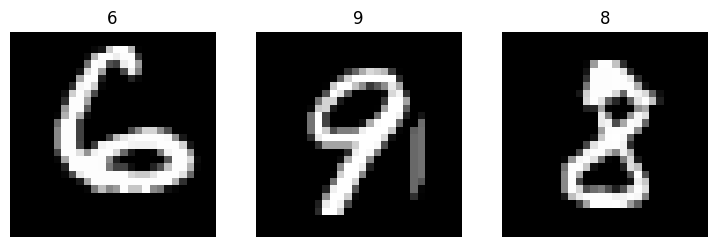

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=10000, random_state=42, stratify=y)

plt.figure(figsize=(9, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

In [4]:
# подвыборка 10 тыс. для сравнения методов
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=10000, random_state=42, stratify=y_train)
X_sub.shape

(10000, 784)

In [5]:
def plot_embedding(emb, labels, title, ax):
    for digit in range(10):
        idx = labels == digit
        ax.scatter(emb[idx, 0], emb[idx, 1], s=3, alpha=0.5, color=plt.cm.tab10(digit), label=str(digit))
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def knn_cv(emb, labels):
    knn = KNeighborsClassifier(n_neighbors=5)
    return cross_val_score(knn, emb, labels, cv=5, scoring='accuracy').mean()

In [6]:
models = {
    'PCA': PCA(n_components=2, random_state=42),
    'SVD': TruncatedSVD(n_components=2, algorithm='arpack', random_state=42),
    'Randomized SVD': TruncatedSVD(n_components=2, algorithm='randomized', random_state=42),
    'LLE': LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42),
    't-SNE': TSNE(n_components=2, random_state=42),
    'UMAP': umap.UMAP(n_components=2, random_state=42, n_jobs=1),
}

embeddings = {}
rows = []
for name, model in models.items():
    start = time.perf_counter()
    emb = model.fit_transform(X_sub)
    fit_time = time.perf_counter() - start
    embeddings[name] = emb
    rows.append({'method': name,
                 'knn_accuracy': knn_cv(emb, y_sub),
                 'silhouette': silhouette_score(emb, y_sub),
                 'time_sec': fit_time})
    print(name, 'done')

# для сравнения: kNN на исходных 784 пикселях
rows.append({'method': 'без сжатия (784 пикселя)',
             'knn_accuracy': knn_cv(X_sub, y_sub),
             'silhouette': silhouette_score(X_sub, y_sub),
             'time_sec': 0})

results = pd.DataFrame(rows).sort_values('knn_accuracy', ascending=False)
results.round(3)

PCA done
SVD done
Randomized SVD done


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__


LLE done
t-SNE done
UMAP done


,method,knn_accuracy,silhouette,time_sec
4,t-SNE,0.948,0.337,21.001
6,без сжатия (784 пикселя),0.943,0.043,0.000
5,UMAP,0.943,0.424,32.376
3,LLE,0.744,0.078,33.818
0,PCA,0.411,0.017,0.247
2,Randomized SVD,0.305,-0.034,0.118
1,SVD,0.305,-0.034,0.285


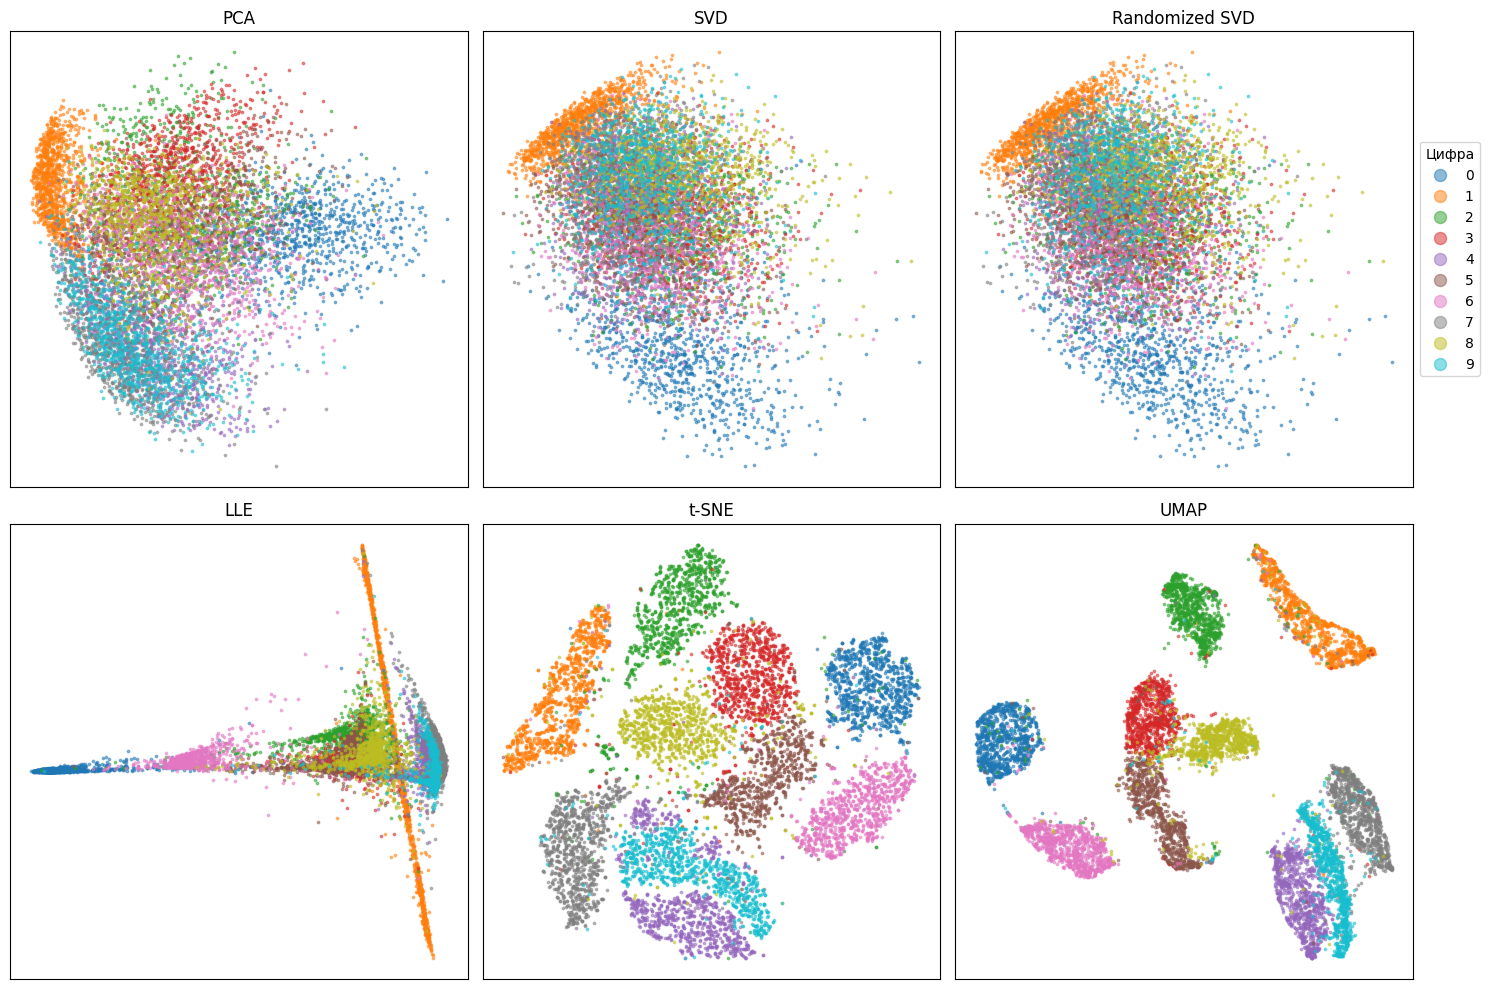

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, emb) in zip(axes.ravel(), embeddings.items()):
    plot_embedding(emb, y_sub, name, ax)
axes[0, 2].legend(title='Цифра', markerscale=5, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig('images/mnist_methods.png', dpi=100, bbox_inches='tight')
plt.show()

**Выводы по методам:**

- Лучше всех цифры разделяют t-SNE и UMAP: kNN по двум числам угадывает 94-95%, это столько же, сколько kNN по всем 784 пикселям (0.943). То есть почти вся информация о том, какая это цифра, поместилась в 2 числа.
- По kNN t-SNE чуть впереди (0.948 против 0.943), но у UMAP заметно лучше silhouette (0.42 против 0.34): кластеры плотнее и дальше друг от друга. И UMAP почти в 2 раза быстрее, и у него есть `transform`, поэтому для сохранения модели я взял его.
- Линейные методы дают кашу: у PCA 0.41, у SVD 0.31. Две компоненты PCA объясняют всего 17% дисперсии, а цифры отличаются нелинейно. Отдельно видны только 0 и 1.
- SVD хуже PCA, потому что не центрирует данные: первая компонента уходит на "среднюю цифру", и для разделения остаётся по сути одна ось. Randomized SVD дал ровно то же, что обычный: для 2 компонент приближение получается точным, а по времени на такой маленькой задаче разницы почти нет.
- LLE посередине (0.74): классы вытянуты в "лучи" из одной точки. Он сохраняет только локальных соседей, а как лучи расположены друг относительно друга, ему всё равно. И он самый медленный.

### Что теряется при сжатии до 2 компонент

Восстановим цифры обратно из 2 и из 50 компонент PCA.

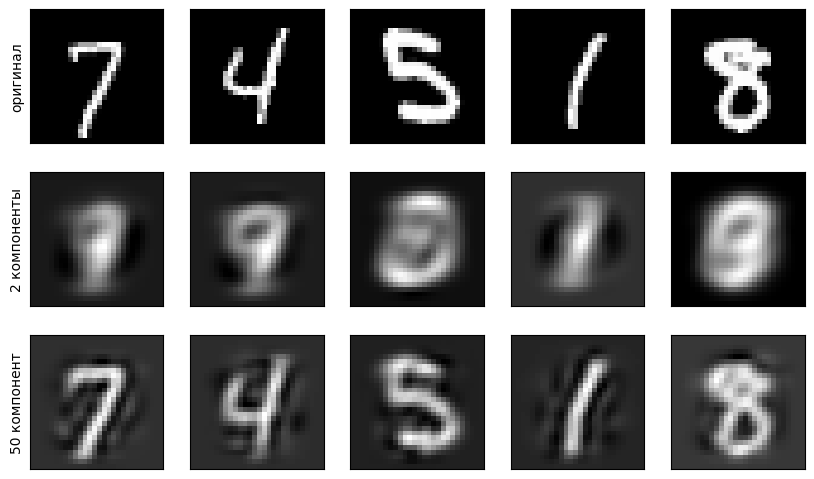

объяснённая дисперсия, 2 компоненты: 0.169
объяснённая дисперсия, 50 компонент: 0.825


In [8]:
pca_2 = PCA(n_components=2).fit(X_train)
pca_50 = PCA(n_components=50).fit(X_train)

rec_2 = pca_2.inverse_transform(pca_2.transform(X_test[:5]))
rec_50 = pca_50.inverse_transform(pca_50.transform(X_test[:5]))

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i in range(5):
    axes[0, i].imshow(X_test[i].reshape(28, 28), cmap='gray')
    axes[1, i].imshow(rec_2[i].reshape(28, 28), cmap='gray')
    axes[2, i].imshow(rec_50[i].reshape(28, 28), cmap='gray')
axes[0, 0].set_ylabel('оригинал')
axes[1, 0].set_ylabel('2 компоненты')
axes[2, 0].set_ylabel('50 компонент')
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

print('объяснённая дисперсия, 2 компоненты:', pca_2.explained_variance_ratio_.sum().round(3))
print('объяснённая дисперсия, 50 компонент:', pca_50.explained_variance_ratio_.sum().round(3))

Из 2 компонент PCA все цифры восстанавливаются в одно и то же размытое пятно, а из 50 (82% дисперсии) уже легко читаются. Для визуализации 2 компоненты PCA мало, а для сжатия перед моделью 50 вполне хватает.

### Сохраняем модель

UMAP оказался лучшим из методов, у которых есть `transform`. Обучаем его на всех 60 тыс. картинках, сверху kNN, и проверяем на отложенных 10 тыс. Модели сохраняем в `models/` (UMAP весит около 400 МБ, потому что хранит обучающие данные, поэтому в репозиторий он не попадает): их загружает ноутбук `predict_my_digits.ipynb` и распознаёт цифры, нарисованные от руки.

In [9]:
umap_mnist = umap.UMAP(n_components=2, random_state=42, n_jobs=1)
X_train_umap = umap_mnist.fit_transform(X_train)
X_test_umap = umap_mnist.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_umap, y_train)
print('test accuracy, UMAP 2D + kNN:', accuracy_score(y_test, knn.predict(X_test_umap)))

dump(umap_mnist, 'models/umap_mnist.joblib')
dump(knn, 'models/knn_mnist.joblib')

test accuracy, UMAP 2D + kNN: 0.9538


['models/knn_mnist.joblib']

In [10]:
# сжатые векторы первых трёх тестовых цифр: после загрузки модели должны получиться те же числа
print(y_test[:3])
X_test_umap[:3]

[7 4 5]


array([[-3.3602817,  0.6085096],
       [-0.4879042, -3.8389692],
       [ 4.0427847,  2.7962635]], dtype=float32)

## 3. Сжатие картинок через SVD

Чёрно-белая картинка это просто матрица яркостей. Раскладываем её через SVD и оставляем только первые $k$ компонент: $M_k = U_k \Sigma_k V_k^T$. Это лучшее приближение матрицы рангом $k$. Хранить нужно $k \cdot (m + n + 1)$ чисел вместо $m \cdot n$.

**Объяснённая дисперсия** (energy) для ранга $k$: доля $\sum_{i \le k} \sigma_i^2 / \sum_i \sigma_i^2$. Сумма квадратов всех сингулярных чисел равна сумме квадратов всех пикселей, поэтому эта доля показывает, какую часть "информации" картинки сохраняют первые $k$ компонент. Данные тут не центрируются, поэтому первая компонента забирает среднюю яркость картинки и почти всегда сразу даёт 80-90%. Смотреть интереснее на порог 99%.

In [11]:
def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return img / 255


def show_ranks(img, ks, title=''):
    U, S, VT = np.linalg.svd(img, full_matrices=False)
    m, n = img.shape
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, k in zip(axes.ravel(), ks):
        img_rec = U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]
        ax.imshow(np.clip(img_rec, 0, 1), cmap='gray')
        ratio = k * (m + n + 1) / (m * n)
        ax.set_title(f'k = {k}, {ratio:.1%} от размера')
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
    return S

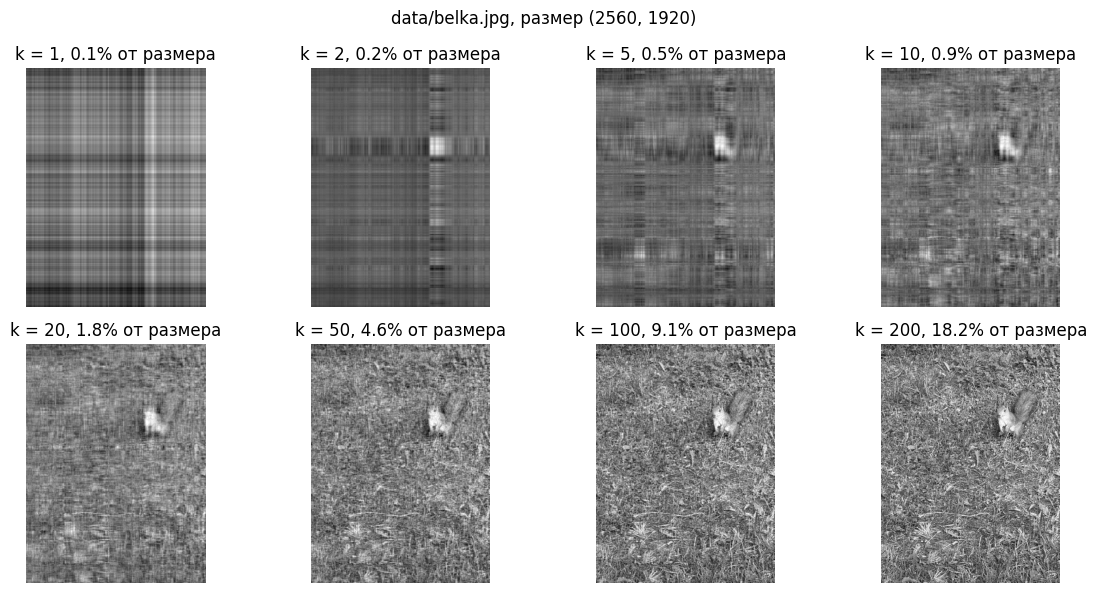

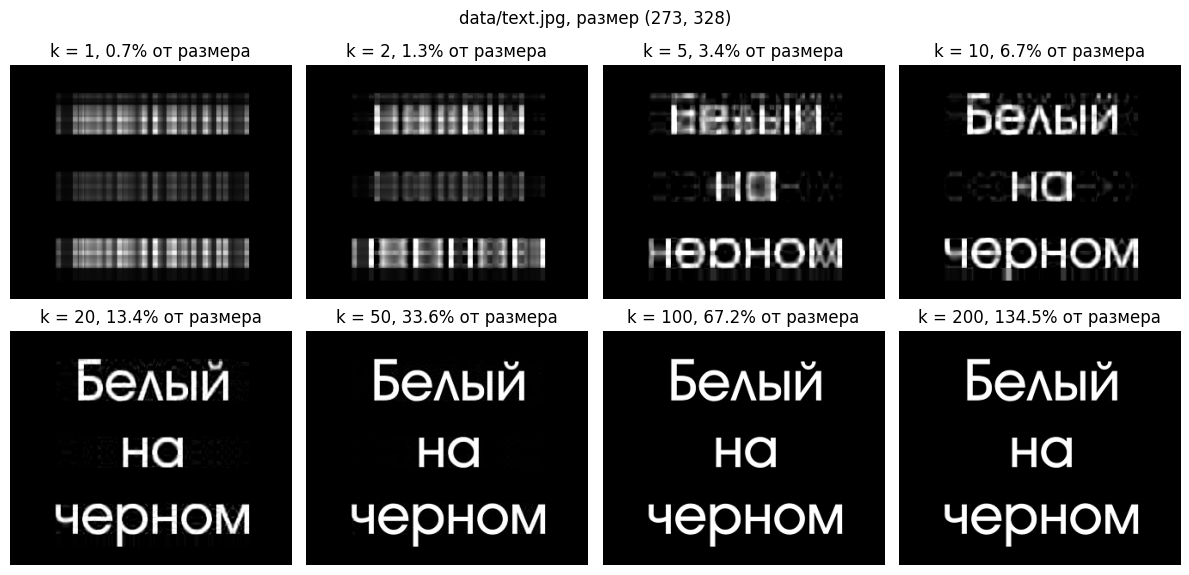

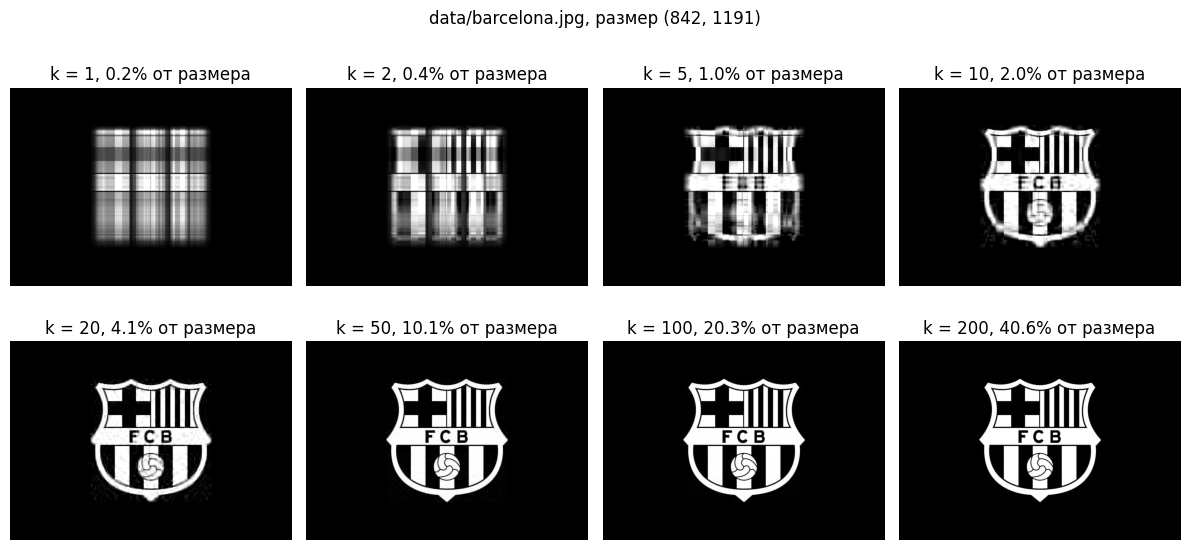

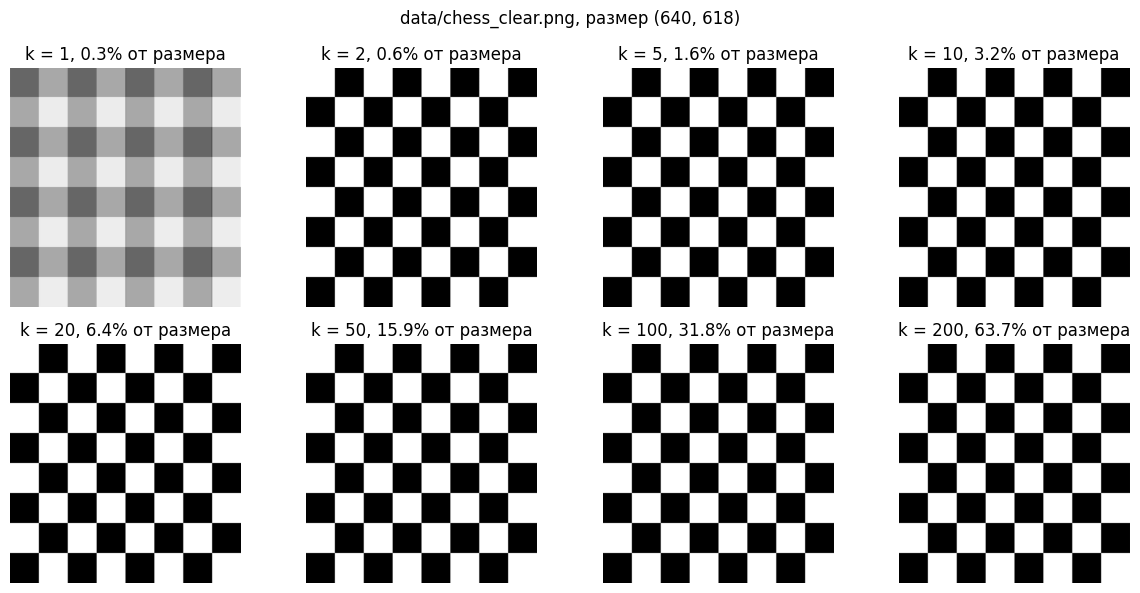

In [12]:
image_paths = ['data/belka.jpg', 'data/text.jpg', 'data/barcelona.jpg', 'data/chess_clear.png']
ks = [1, 2, 5, 10, 20, 50, 100, 200]

spectra = {}
for path in image_paths:
    img = load_gray(path)
    spectra[path] = show_ranks(img, ks, title=f'{path}, размер {img.shape}')

data/belka.jpg: 90% дисперсии при k = 17, 99% при k = 266, всего компонент 1920
data/text.jpg: 90% дисперсии при k = 10, 99% при k = 30, всего компонент 273
data/barcelona.jpg: 90% дисперсии при k = 6, 99% при k = 36, всего компонент 842
data/chess_clear.png: 90% дисперсии при k = 2, 99% при k = 2, всего компонент 618


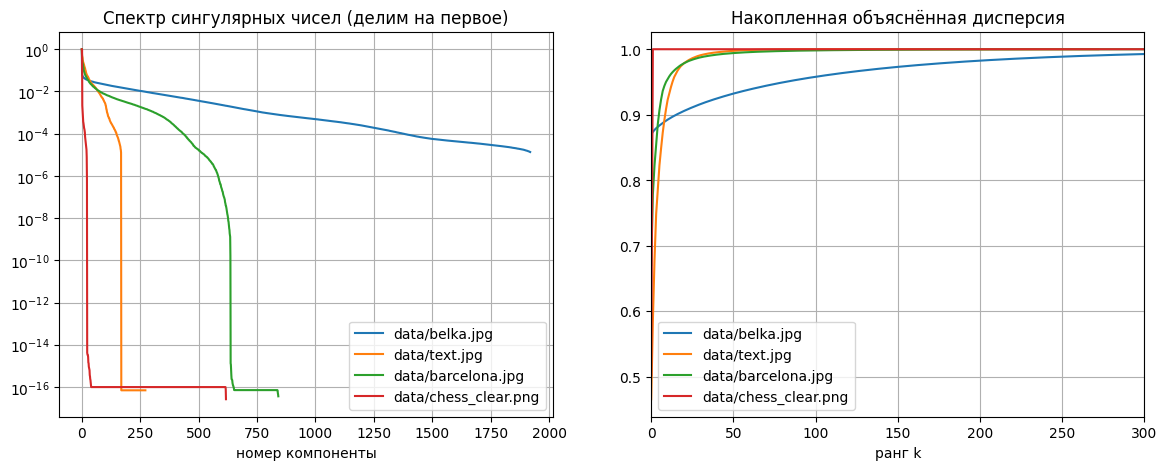

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for path, S in spectra.items():
    explained = S ** 2 / np.sum(S ** 2)
    axes[0].semilogy(S / S[0], label=path)
    axes[1].plot(np.cumsum(explained), label=path)

    k90 = np.argmax(np.cumsum(explained) >= 0.90) + 1
    k99 = np.argmax(np.cumsum(explained) >= 0.99) + 1
    print(f'{path}: 90% дисперсии при k = {k90}, 99% при k = {k99}, всего компонент {len(S)}')

axes[0].set_title('Спектр сингулярных чисел (делим на первое)')
axes[0].set_xlabel('номер компоненты')
axes[1].set_title('Накопленная объяснённая дисперсия')
axes[1].set_xlabel('ранг k')
axes[1].set_xlim(0, 300)
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

### Цветная картинка

Цветная картинка это три матрицы (R, G, B). Раскладываем каждую отдельно и собираем обратно.

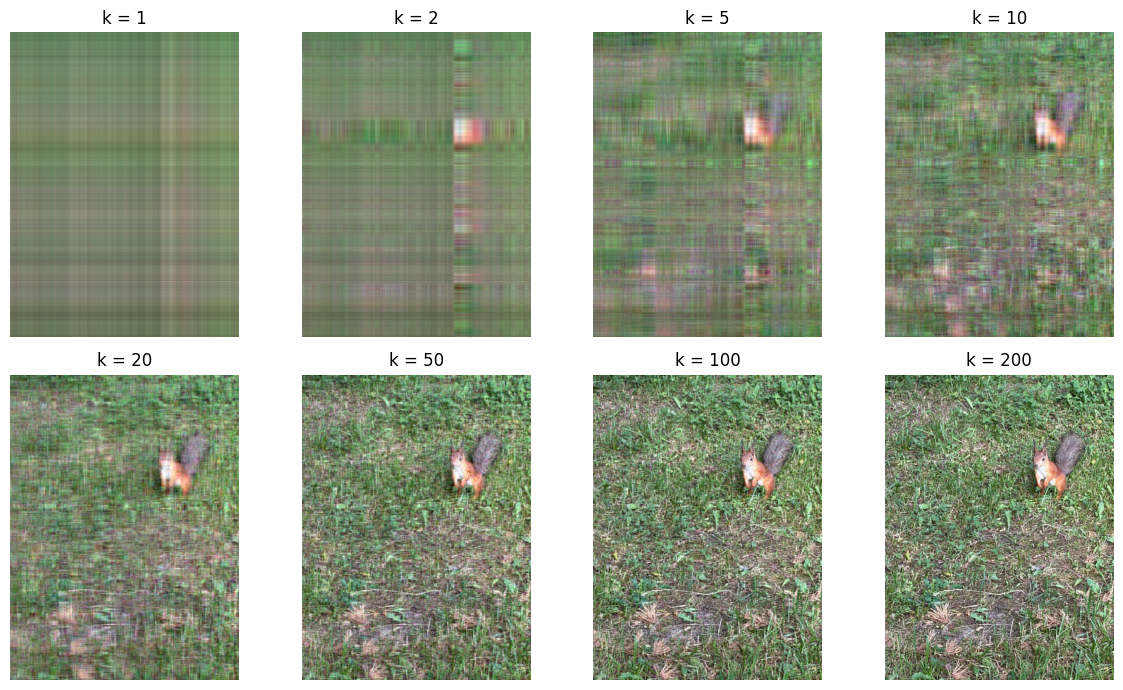

In [14]:
image = cv2.cvtColor(cv2.imread('data/belka.jpg'), cv2.COLOR_BGR2RGB) / 255

channels = []
for c in range(3):
    channels.append(np.linalg.svd(image[:, :, c], full_matrices=False))

fig, axes = plt.subplots(2, 4, figsize=(12, 7))
for ax, k in zip(axes.ravel(), ks):
    rec = []
    for U, S, VT in channels:
        rec.append(U[:, :k] @ np.diag(S[:k]) @ VT[:k, :])
    img_rec = np.clip(np.stack(rec, axis=2), 0, 1)
    ax.imshow(img_rec)
    ax.set_title(f'k = {k}')
    ax.axis('off')
plt.tight_layout()
plt.savefig('images/svd_compression.png', dpi=80, bbox_inches='tight')
plt.show()

**Выводы по сжатию:**

- Спектр сингулярных чисел быстро падает: первые несколько компонент несут большую часть картинки, дальше идут мелкие детали и шум.
- Сколько компонент нужно, сильно зависит от картинки. Чистой шахматной доске хватает 2 (это матрица ранга 2), тексту хватает 20-30, фото города около 40. Белке на траве нужно 100-200: трава это мелкая нерегулярная текстура, её SVD сжимает плохо.
- У текста спектр обрывается примерно на 170-й компоненте: у картинки много полностью чёрных строк и столбцов, поэтому её настоящий ранг меньше размера.
- Сжатие выгодно, пока $k (m + n + 1) < m n$. У маленькой картинки с текстом при $k = 200$ хранить пришлось бы больше, чем сам оригинал (134%), а у белки 2560x1920 даже $k = 200$ это 18% от размера.
- На маленьких рангах видны горизонтальные и вертикальные полосы: каждая компонента это произведение столбца на строку, поэтому SVD лучше всего сжимает то, что выровнено по осям.

## 4. Фон на видео через SVD

Видео с неподвижной камеры: каждый кадр вытягиваем в строку, получаем матрицу "кадры x пиксели". Фон почти одинаковый во всех кадрах, поэтому он попадает в первые компоненты SVD, а движущиеся машины и люди в остальные. Если восстановить кадр с маленьким рангом, останется только фон, а разность кадра и фона покажет то, что движется.

In [15]:
cap = cv2.VideoCapture('data/Video_008.avi')
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
cap.release()

frames = np.array(frames)
n_frames, h, w = frames.shape
print(frames.shape)

M = frames.reshape(n_frames, -1) / 255
M.shape

(792, 240, 320)


(792, 76800)

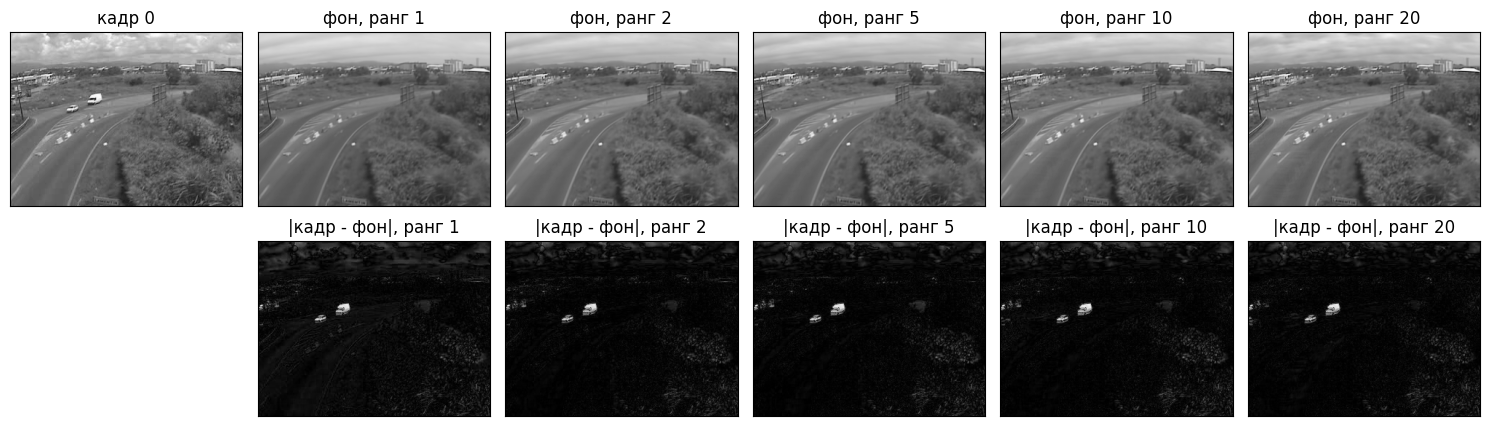

In [16]:
ranks = [1, 2, 5, 10, 20]

fig, axes = plt.subplots(2, len(ranks) + 1, figsize=(15, 4.5))
axes[0, 0].imshow(M[0].reshape(h, w), cmap='gray', vmin=0, vmax=1)
axes[0, 0].set_title('кадр 0')
axes[1, 0].axis('off')

for i, k in enumerate(ranks):
    svd = TruncatedSVD(n_components=k, random_state=42)
    low = svd.fit_transform(M)
    background = svd.inverse_transform(low[[0]])[0]
    foreground = np.abs(M[0] - background)

    axes[0, i + 1].imshow(background.reshape(h, w), cmap='gray', vmin=0, vmax=1)
    axes[0, i + 1].set_title(f'фон, ранг {k}')
    axes[1, i + 1].imshow(foreground.reshape(h, w), cmap='gray')
    axes[1, i + 1].set_title(f'|кадр - фон|, ранг {k}')

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

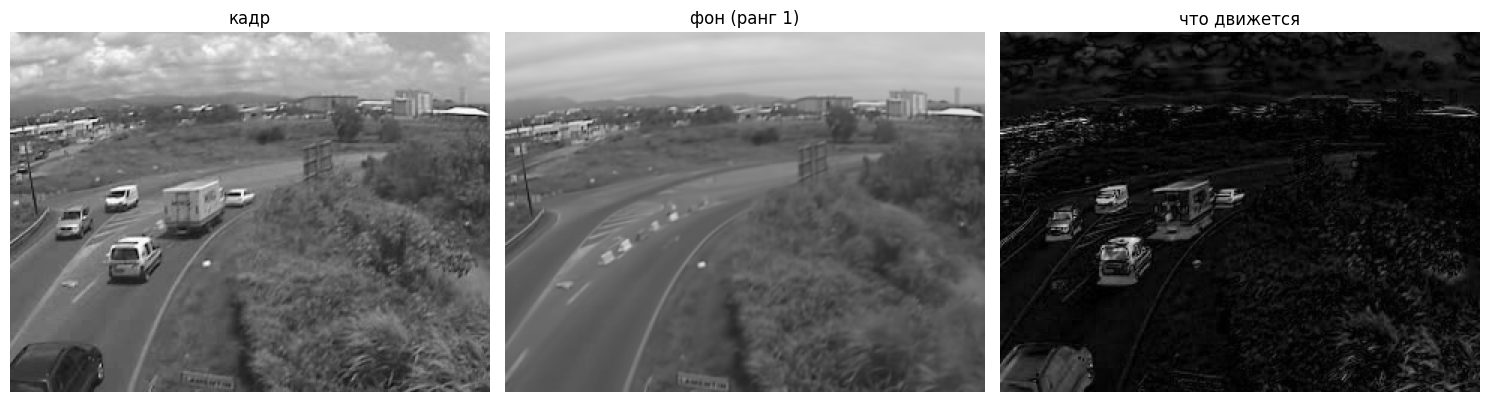

In [17]:
# картинка для README: кадр, фон ранга 1 и то, что движется
svd = TruncatedSVD(n_components=1, random_state=42)
low = svd.fit_transform(M)
frame_id = n_frames // 2
background = svd.inverse_transform(low[[frame_id]])[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(M[frame_id].reshape(h, w), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('кадр')
axes[1].imshow(background.reshape(h, w), cmap='gray', vmin=0, vmax=1)
axes[1].set_title('фон (ранг 1)')
axes[2].imshow(np.abs(M[frame_id] - background).reshape(h, w), cmap='gray')
axes[2].set_title('что движется')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig('images/video_background.png', dpi=80, bbox_inches='tight')
plt.show()

**Выводы по видео:**

- Для фона хватает ранга 1: фон почти не меняется между кадрами, поэтому всё видео почти целиком описывается одной компонентой. Машины в неё не попадают, и разность кадра с фоном показывает только их.
- С рангом 5-20 в разности меньше шума от травы и облаков (они тоже немного двигаются), но если брать ранг слишком большим, в "фон" начнут попадать и сами машины. Для простого отделения фона ранга 1-2 достаточно.

## 5. Бонус: добавляем лицу улыбку

Данные: [CelebA](https://www.kaggle.com/datasets/jessicali9530/celeba-dataset), фото знаменитостей. Лица уже выровнены (глаза примерно в одном месте), и у каждого фото есть метка `Smiling`. Датасет скачивается прямо из кода через `kagglehub`. Берём первые 10 тыс. фото, переводим в чёрно-белые, вырезаем центр с лицом и уменьшаем до 64x64.

Идея: сжимаем все лица через PCA и считаем среднее улыбающееся и среднее неулыбающееся лицо в пространстве компонент. Разница между ними это "направление улыбки". Если прибавить его к лицу и восстановить картинку, лицо должно начать улыбаться, а если вычесть, перестать.

In [18]:
import kagglehub

# скачивается один раз (около 1.4 ГБ) и дальше берётся из кэша
celeba_path = kagglehub.dataset_download('jessicali9530/celeba-dataset')
img_folder = os.path.join(celeba_path, 'img_align_celeba', 'img_align_celeba')
attrs = pd.read_csv(os.path.join(celeba_path, 'list_attr_celeba.csv')).head(10000)


def load_face(file):
    img = cv2.imread(os.path.join(img_folder, file), cv2.IMREAD_GRAYSCALE)
    img = img[55:163, 35:143]  # исходник 218x178, вырезаем центр 108x108 с лицом
    img = cv2.resize(img, (64, 64))
    return img / 255


faces = np.array([load_face(file).ravel() for file in attrs['image_id']])
smiling = (attrs['Smiling'] == 1).values
print(faces.shape, 'улыбаются:', smiling.mean().round(2))

(10000, 4096) улыбаются: 0.48


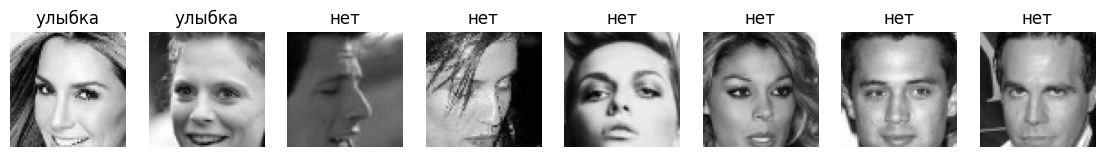

In [19]:
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(faces[i].reshape(64, 64), cmap='gray')
    ax.set_title('улыбка' if smiling[i] else 'нет')
    ax.axis('off')
plt.show()

### NMF: из каких "частей" складываются лица

Для сравнения с SVD (вопрос 1.3) посмотрим на компоненты NMF: они неотрицательные, поэтому должны получаться похожими на отдельные части лица.

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


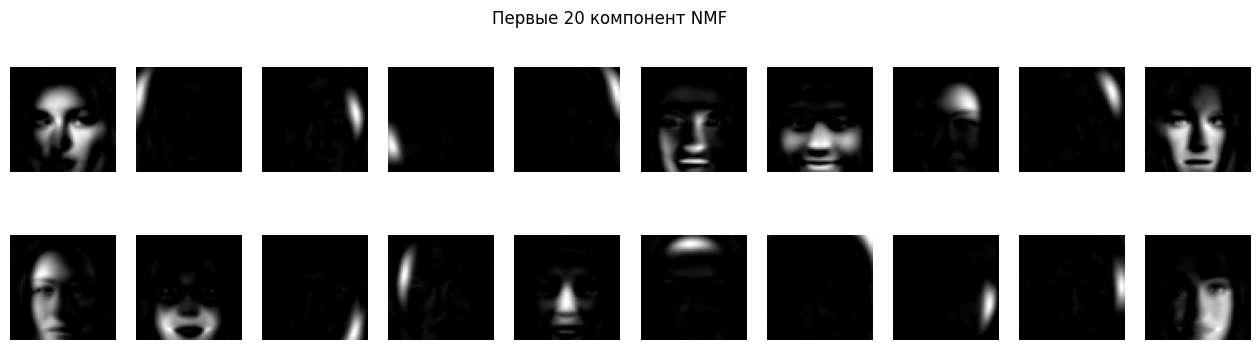

In [20]:
nmf_faces = NMF(n_components=50, init='nndsvda', max_iter=500, random_state=42)
W = nmf_faces.fit_transform(faces)

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(nmf_faces.components_[i].reshape(64, 64), cmap='gray')
    ax.axis('off')
plt.suptitle('Первые 20 компонент NMF')
plt.show()

объяснённая дисперсия: 0.948


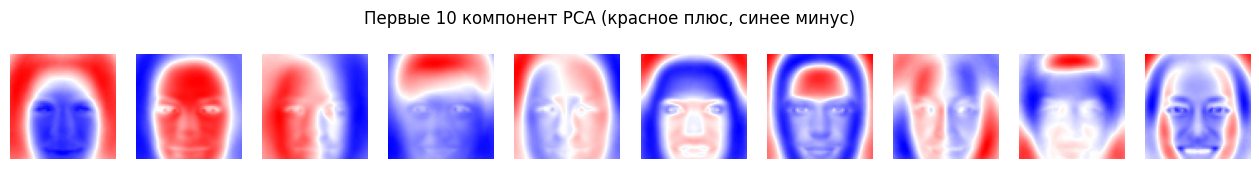

In [21]:
# для сравнения: первые компоненты PCA, они "целые лица" с плюсами и минусами
pca_faces = PCA(n_components=200, random_state=42)
faces_pca = pca_faces.fit_transform(faces)
print('объяснённая дисперсия:', pca_faces.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for i, ax in enumerate(axes):
    ax.imshow(pca_faces.components_[i].reshape(64, 64), cmap='bwr')
    ax.axis('off')
plt.suptitle('Первые 10 компонент PCA (красное плюс, синее минус)')
plt.show()

### Направление улыбки

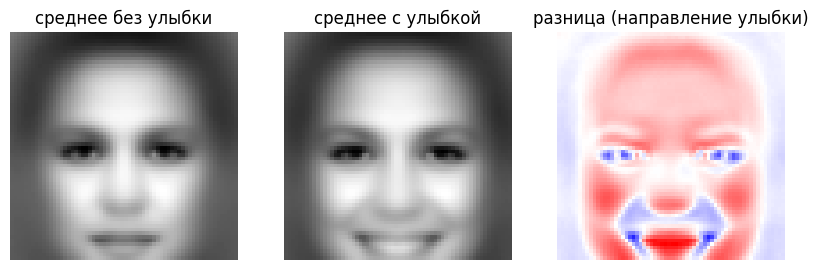

In [22]:
smile_direction = faces_pca[smiling].mean(axis=0) - faces_pca[~smiling].mean(axis=0)

mean_smile = pca_faces.inverse_transform(faces_pca[smiling].mean(axis=0).reshape(1, -1))
mean_no_smile = pca_faces.inverse_transform(faces_pca[~smiling].mean(axis=0).reshape(1, -1))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(mean_no_smile.reshape(64, 64), cmap='gray')
axes[0].set_title('среднее без улыбки')
axes[1].imshow(mean_smile.reshape(64, 64), cmap='gray')
axes[1].set_title('среднее с улыбкой')
diff = (mean_smile - mean_no_smile).reshape(64, 64)
lim = np.abs(diff).max()
axes[2].imshow(diff, cmap='bwr', vmin=-lim, vmax=lim)
axes[2].set_title('разница (направление улыбки)')
for ax in axes:
    ax.axis('off')
plt.show()

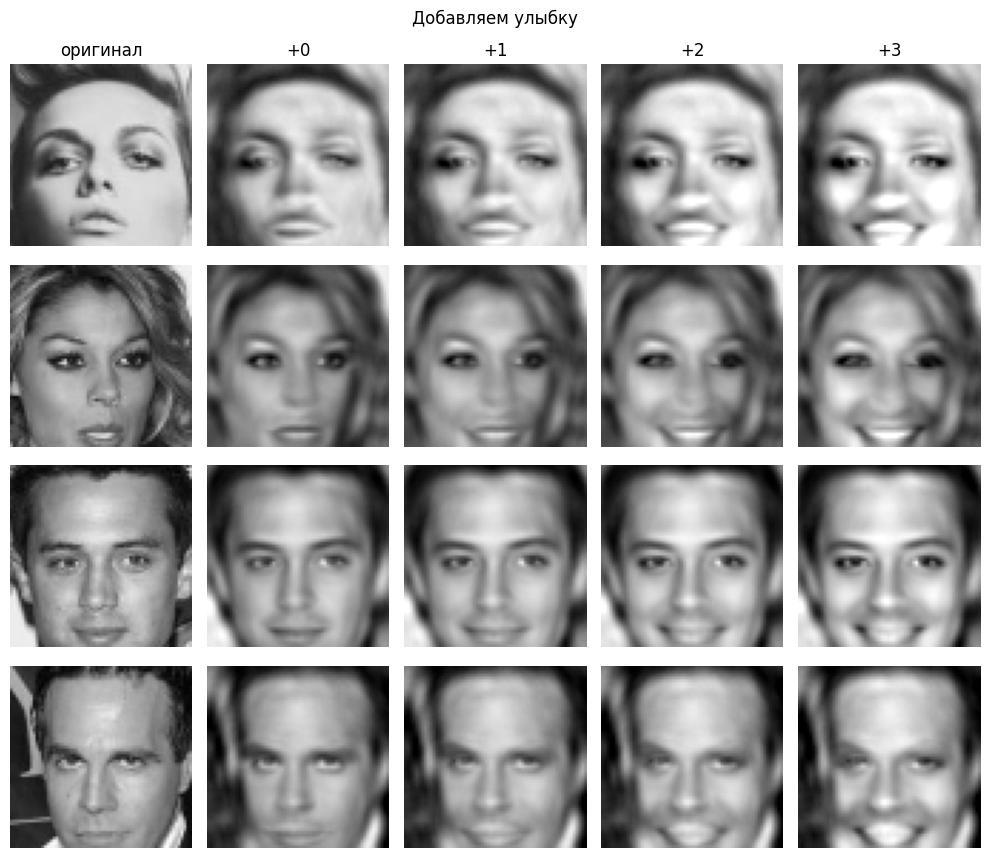

In [23]:
def show_steps(ind_list, coefs, title, save_path=None):
    fig, axes = plt.subplots(len(ind_list), len(coefs) + 1, figsize=(2 * (len(coefs) + 1), 2.2 * len(ind_list)))
    for row, ind in enumerate(ind_list):
        axes[row, 0].imshow(faces[ind].reshape(64, 64), cmap='gray', vmin=0, vmax=1)
        for col, coef in enumerate(coefs):
            face = pca_faces.inverse_transform((faces_pca[ind] + coef * smile_direction).reshape(1, -1))
            axes[row, col + 1].imshow(np.clip(face, 0, 1).reshape(64, 64), cmap='gray', vmin=0, vmax=1)
            if row == 0:
                axes[row, col + 1].set_title(f'{coef:+}')
        if row == 0:
            axes[row, 0].set_title('оригинал')
    for ax in axes.ravel():
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=80, bbox_inches='tight')
    plt.show()


# 0 это просто восстановление из 200 компонент PCA, дальше прибавляем направление улыбки
no_smile_ind = np.where(~smiling)[0][2:6]
show_steps(no_smile_ind, [0, 1, 2, 3], 'Добавляем улыбку', save_path='images/add_smile.png')

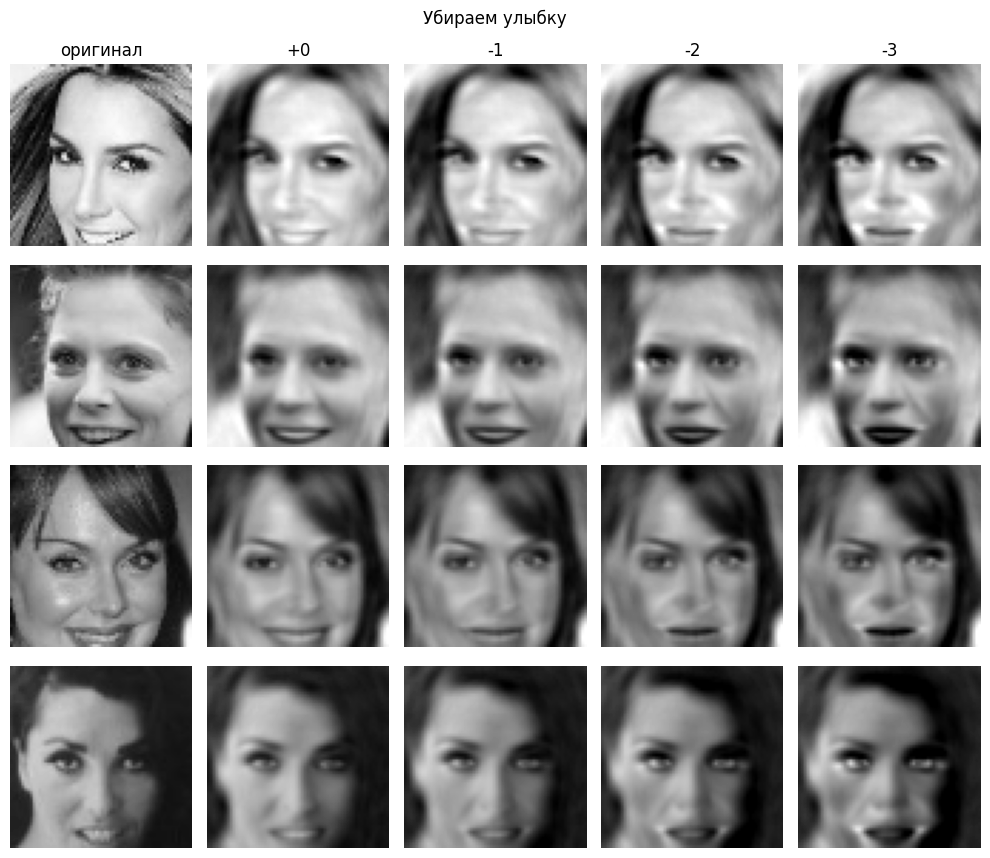

In [24]:
smile_ind = np.where(smiling)[0][:4]
show_steps(smile_ind, [0, -1, -2, -3], 'Убираем улыбку')

**Выводы по лицам:**

- На выровненных лицах всё заработало: 200 компонент PCA сохраняют 95% дисперсии, и человек на восстановленной картинке узнаётся, только чуть размыт.
- Направление улыбки получилось осмысленным: на картинке разницы светлеют зубы и щёки, а уголки рта и глаза темнеют (при улыбке глаза щурятся). Но всё лицо в разнице тоже немного красное: на фото с улыбкой лица в среднем светлее, и это направление выучило заодно и яркость.
- При шаге +1 и +2 человек остаётся собой, а улыбка появляется. На +3 появляются белые пятна на щеках, лицо начинает уходить в "среднюю улыбку". В обратную сторону так же: на -1 улыбка пропадает, на -2 и -3 рот становится тёмным пятном.
- Лучше всего работает на лицах в анфас. Если голова повёрнута, направление улыбки ложится не туда (оно посчитано по среднему лицу, которое смотрит прямо), поэтому для примера я взял лица, которые смотрят в камеру.
- NMF на таких данных и правда находит части: отдельно рот с зубами, нос, лоб, волосы и тени слева и справа. У PCA компоненты "целые": свет слева или справа, фон, общая форма головы, с плюсами и минусами. На грязном датасете с эмоциями (сначала был он) NMF такого не находил: там лица не выровнены, есть профили, руки и вообще не лица.